What is Backtracking ?

Backtracking is an algorithmic technique for exploring possible solutions by building a solution incrementally, abandoning a path when it cannot lead to a valid result, and trying another path.
                        OR
Backtracking is a problem-solving technique where you:
    Build a solution incrementally -> Check constraints -> If invalid, undo (backtrack) and try another path. 

It is essentially a systematic DFS (Depth-First Search) over the solution space. 

Imagine an AI workflow planner that must choose a sequence of tools:
    
    - A tool can run only if its dependencies are satisfied.
    - Certain tools cannot be used together.
    - The workflow must meet a specified goal.

You might select Tool A, then Tool B, discover that Tool C cannot execute, undo Tool B, and try Tool D.

That's backtracking.

The same reasoning applies to permutations, Sudoku, N-Queens, combinations, and constrained workflow scheduling.

Intuition: 

Think of it like solving a maZE:
    - You try a path 
    - If it leads to a dead end -> go back 
    - Try a different path 
    - Repeat until you find a valid solution (or all solutions)


In [ ]:
# Core idea (Template)

def backtrack(path, choices):
    if is_solution(path):
        result.append(path.copy())
        return 
    
    for choice in choices: 
        if not is_valid(choice, path):
            continue

        # choose 
        path.append(choice)

        # explore
        backtrack(path, choices)

        # un-choose (BACKTRACK)
        path.pop() 

Key Characteristics 

- Explores all possible configurations 
- Uses recursion + pruning 
- Often exponential: O(2^n), O(n!), etc
- Works best when: 
    - You need all solutions 
    - constraints can prune space early 

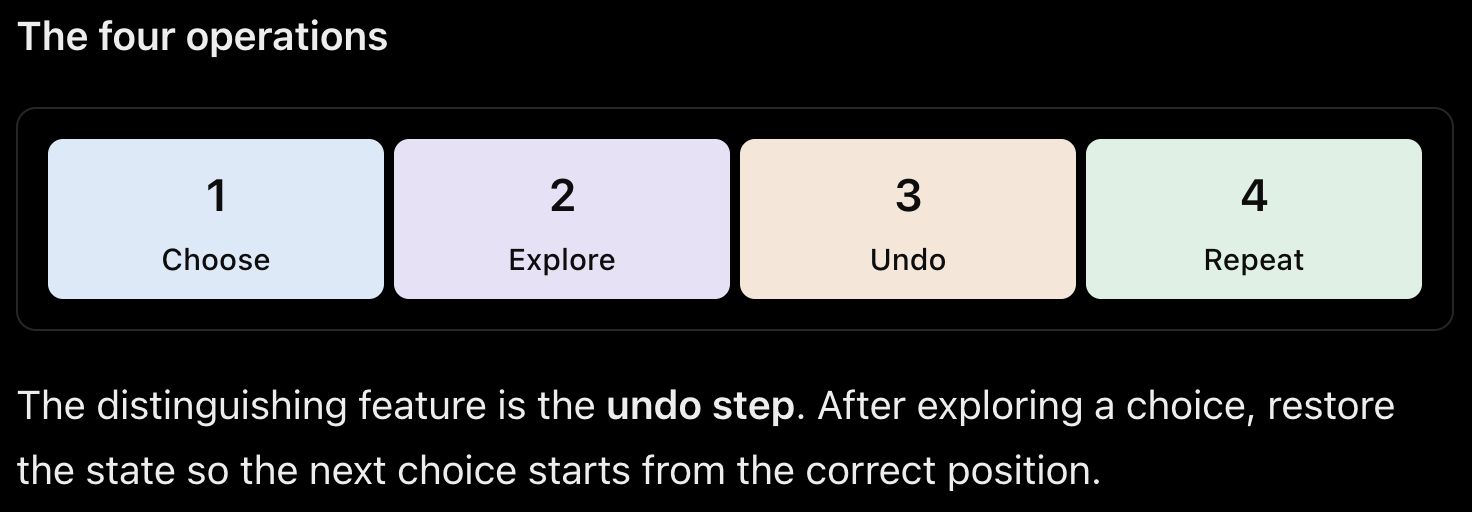


2. How do you recognize a Backtracking problem ?

Look for these clues inthe problem statement. 

Wording                                     Likely Pattern 
"Find all possible combinations"            Subsets / combinations 
"Generate all arrangements"                 Permutations 
"Find all valid configurations"             Constraint Backtracking
"Can you form this word in a grid?"         DFS + Bcktracking 
"Partition into valid groups"               Partitioning 
"Find all paths satisfying conditions"      DFS + Backtracking 

Backtracking vs DFS vs Dynamic Programming 

DFS     - Explore deeply through a graph / tree
Backtracking - Explore decisions, undo, try alternatives 
Dynamic Programming - Reuse answers to overlapping subproblems 
Greedy  - Make a locally optimal choice without recosnidering it

Backtracking is often implemented using recursive DFS. They are not mutually exclusive. 

The Universal Python template:

In [ ]:
def backtrack(path, choices):
    # 1. Base case
    if is_solution(path):
        results.append(path.copy())
        return

    # 2. Explore available choices
    for choice in choices:
        if not is_valid(choice, path):
            continue

        # 3. Choose
        path.append(choice)

        # 4. Explore
        backtrack(path, next_choices(choice))

        # 5. Undo
        path.pop()

Worked example

Problem #1: 
LeetCode 78 — Subsets

Generate all Subsets 

Given an integer array nums containing unique elements, return its power set—the collection of all possible subsets, including the empty subset and the complete array. Subsets may appear in any order, but no duplicate subsets are allowed. 

For example, nums = [1, 2, 3] 

produces eight subsets: 
[], [1], [2], [3], [1,2], [1,3], [2,3], and [1,2,3]


Step 1: Recognize the pattern 

Every element has two possible decisions:
    * Include it 
    * Exclude it

For n elements, there are 2^n subsets. 

Step 2: Visualize the decision tree 

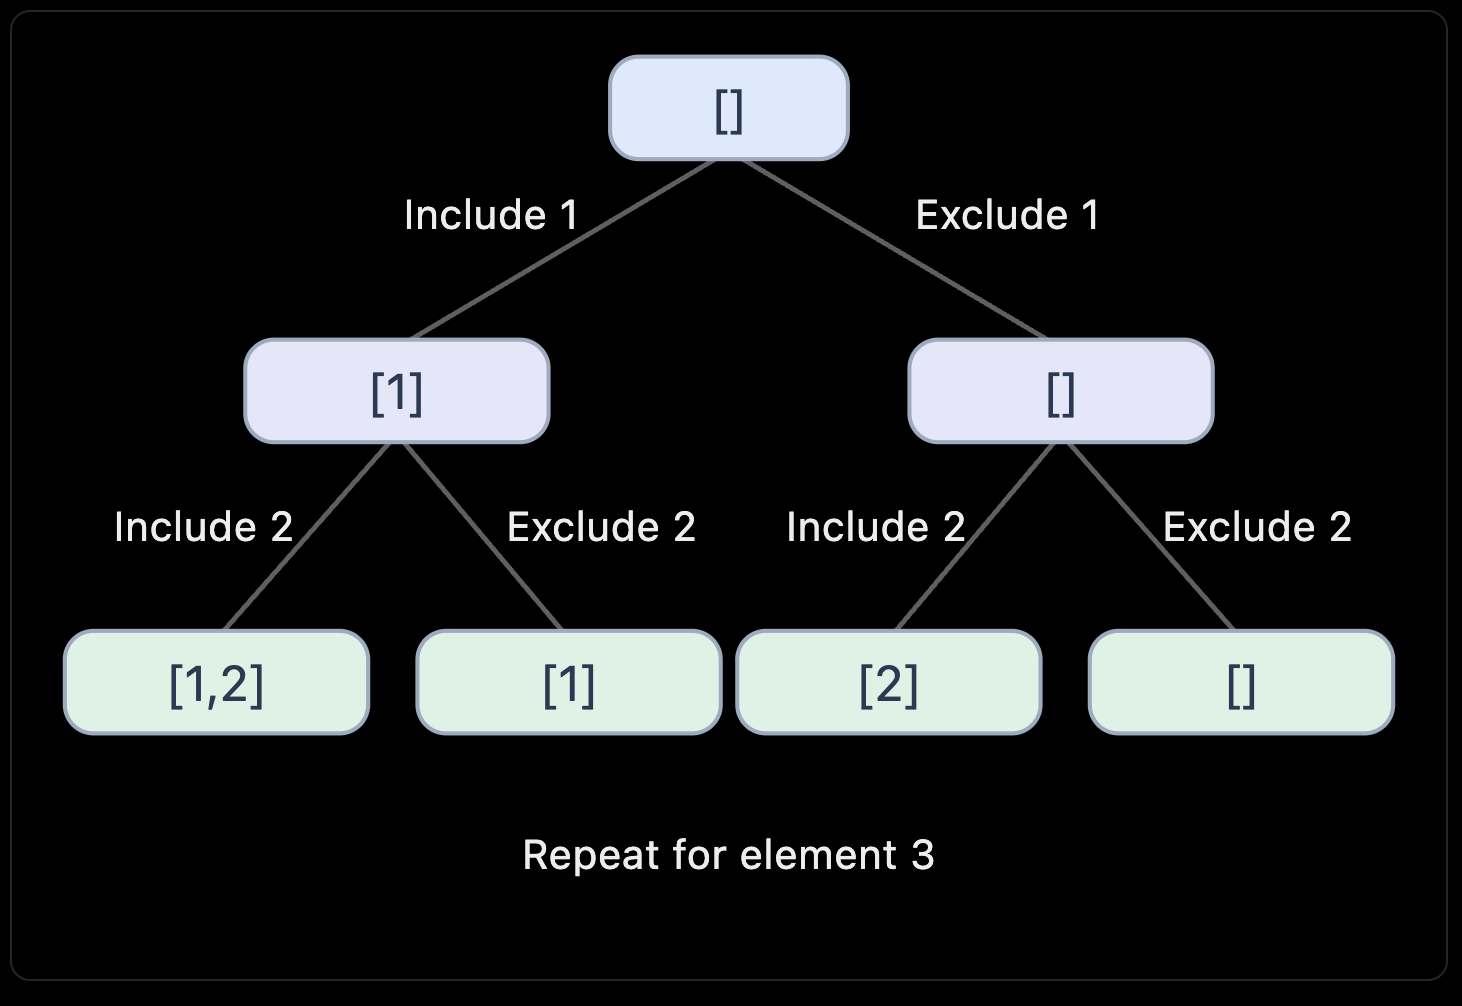


Step 3: Implement it ... 


In [1]:

def subsets(nums):
    result = [] 
    path = [] 

    def backtrack(start):
        result.append(path.copy())

        for i in range(start, len(nums)):
            path.append(nums[i])    # Choose 
            backtrack(i+1)          # explore
            path.pop()              # undo
    backtrack(0)
    return result 

# usage 
print(subsets([1, 2, 3]))

[[], [1], [1, 2], [1, 2, 3], [1, 3], [2], [2, 3], [3]]


Complexity
    - Time: O(n . 2^n), including copying subsets.
    - Auxiliary recursion/path space: O(n).
    - Output storage: O(n . 2^n).

Interview takeaway

When asked to generate all subsets, think: start index + current path + choose/recurse/undo.



In [ ]:
# Another approach 

def get_all_subsets(arr, index=0, current_path=None, result=None):
    # Initialize containers on the first call
    if result is None:
        result = []
    if current_path is None:
        current_path = []
        
    # BASE CASE: When we have made a decision for every element in the array
    if index == len(arr):
        # Append a copy of the current path to our result list
        result.append(list(current_path))
        return result
    
    # CHOICE 1: Include the current element
    current_path.append(arr[index])
    get_all_subsets(arr, index + 1, current_path, result)
    
    # BACKTRACK: Remove the element to try the alternative choice
    current_path.pop()
    
    # CHOICE 2: Exclude the current element
    get_all_subsets(arr, index + 1, current_path, result)
    
    return result

# --- Execution ---
a = [1, 2, 3]
subsets = get_all_subsets(a)

print("All Subsets:")
print(subsets)



In [10]:
# naive method

a = [1, 2, 3]
n = len(a)
result = [] 

for num in a:
    current_len = len(result)

    for i in range(current_len):
        print (i, num)
        existing_subset = list(result[i])
        existing_subset.append(num)
        result.append(existing_subset)

# for i in range(n):
#     for j in range(i+1, n+1):
#         print (a[i:j])
print (result)


[]


In [ ]:
# Naive approach 

def subsets_naive(arr):
    # Start with a list containing just the empty set
    result = [[]]
    
    # Loop through each number in our input array
    for num in arr:
        # Sneak peek at how many subsets we have built so far
        current_length = len(result)
        
        # Duplicate and expand only the subsets that exist right now
        for i in range(current_length):
            # Take an existing subset and make a clean copy of it
            existing_subset = list(result[i])
            
            # Add the current number to that copy
            existing_subset.append(num)
            
            # Put the new combination back into our master list
            result.append(existing_subset)
            
    return result

# --- Execution ---
a = [1, 2, 3]
print("Naive Subsets:")
print(subsets_naive(a))


Naive Subsets:
[[], [1], [2], [1, 2], [3], [1, 3], [2, 3], [1, 2, 3]]


Problem #2 

Generate all permutations (Easy–Medium)

Given an array nums containing distinct integers, return all possible permutations in any order. Each permutation must contain every input element exactly once. 

For example, the input [1,2,3] 

produces six permutations: 
[1,2,3], [1,3,2], [2,1,3], [2,3,1], [3,1,2], and [3,2,1].

Recognition
Unlike subsets, order matters.
[1,2,3] and [2,1,3] are different permutations.
We must ensure each number is used exactly once per permutation.



In [12]:
def permute(nums):
    result = []
    path = []
    used = [False] * len(nums)

    def backtrack():
        if len(path) == len(nums):
            result.append(path.copy())
            return

        for i in range(len(nums)):
            if used[i]:
                continue

            used[i] = True
            path.append(nums[i])

            backtrack()

            path.pop()
            used[i] = False

    backtrack()
    return result


print(permute([1, 2, 3]))

[[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]


In [18]:
arr = [1, 2, 3, 4]
n = len(arr)

for i in range(n):
    print (arr[i::])


[1, 2, 3, 4]
[2, 3, 4]
[3, 4]
[4]


Key difference from subsets
Subsets	                        Permutations
Uses start index	            Uses used array
Order doesn't matter	        Order matters
(2^n\) results	                (n!) results
Partial paths are solutions	    Only full-length paths are solutions

Time complexity: O(n . n!), including output copying.

Auxiliary space: O(n), excluding results.




Problem #3

Given a number N - generate all strings of length N using only the letter 'A' and 'B'




In [19]:
for i in ['a', 'b']:
    for j in ['a', 'b']:
        print (i, '-', j)

a - a
a - b
b - a
b - b
